# Mini-DINO: self-supervised learning without labels

A small version of DINO.

Basic concept : 

A student and a teacher network see different crops of the same image, and the student learns to match the teacher's output. The teacher is a slow moving average (EMA) of the student, and centering + sharpening prevent collapse.

## Step 1: Setup

Imports, GPU check and the settings.

In [1]:
import os, math, time, json, random, shutil

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# output folders
ON_KAGGLE = os.path.exists("/kaggle/working")
BASE_DIR = "/kaggle/working" if ON_KAGGLE else "."
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cpu":
    print("No GPU found! Turn on a GPU in the Kaggle session options, otherwise training will be very slow.")

def set_seed(seed):
    # repeatable runs
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

Using device: cuda


In [2]:
# Settings
SEED = 0

# Data
N_TRAIN = 5000        
N_TEST = 2000

# Multi crop
N_LOCAL = 4          
IMG_SIZE = 32
LOCAL_SIZE = 16

# Small vit
PATCH_SIZE = 4
EMBED_DIM = 192
DEPTH = 6
HEADS = 3
OUT_DIM = 2048        

# Training
EPOCHS = 20
BATCH_SIZE = 64
LEARNING_RATE = 2e-4
WARMUP_EPOCHS = 2
WEIGHT_DECAY = 0.04

# DINO specific
EMA_START = 0.99      
STUDENT_TEMP = 0.1
TEACHER_TEMP_START = 0.04   
TEACHER_TEMP_END = 0.04    
TEACHER_WARMUP_EPOCHS = 6
CENTER_MOMENTUM = 0.9

# Evaluation
EVAL_EVERY = 2

## Step 2: Get the data

CIFAR-10, using a random subset of 5,000 images. Labels are never used for training, only for plots and the k-NN check.

Found local CIFAR-10 at: /kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py
Training images: 5000 | images per class: [503, 483, 487, 527, 473, 548, 491, 502, 482, 504]
Test images    : 2000


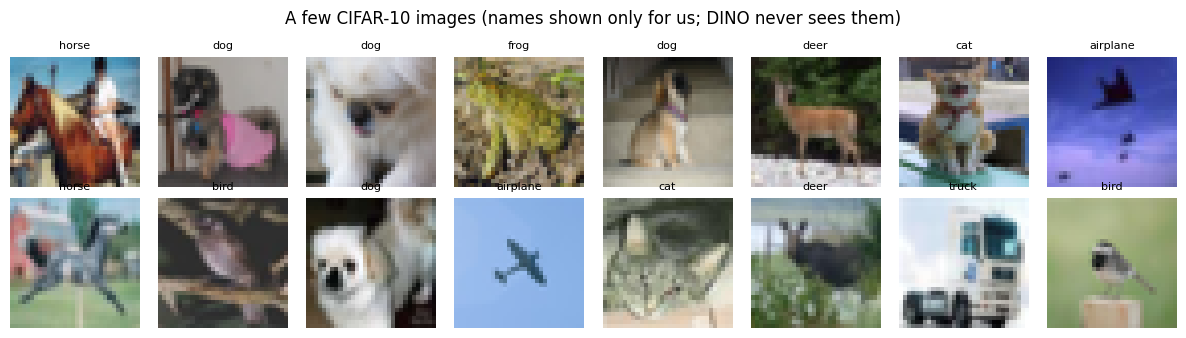

In [3]:
# Download CIFAR-10
def find_cifar_folder():
    for start in ["/kaggle/input", DATA_DIR, "."]:
        for folder, subfolders, files in os.walk(start):
            if "data_batch_1" in files:
                return folder
    return None

cifar_folder = find_cifar_folder()
if cifar_folder is None:
    print("No local CIFAR-10 found, downloading it (needs Internet ON)...")
    data_root, should_download = DATA_DIR, True
else:
    print("Found local CIFAR-10 at:", cifar_folder)
    if os.path.basename(cifar_folder) == "cifar-10-batches-py":
        data_root = os.path.dirname(cifar_folder)
    else:
        data_root = DATA_DIR
        target = os.path.join(DATA_DIR, "cifar-10-batches-py")
        if not os.path.exists(target):
            shutil.copytree(cifar_folder, target)
    should_download = False

train_data = torchvision.datasets.CIFAR10(data_root, train=True, download=should_download)
test_data = torchvision.datasets.CIFAR10(data_root, train=False, download=should_download)
CLASS_NAMES = train_data.classes

# Pick random subsets
rng = np.random.RandomState(SEED)
train_idx = rng.choice(len(train_data), N_TRAIN, replace=False)
test_idx = rng.choice(len(test_data), N_TEST, replace=False)
train_labels = np.array(train_data.targets)[train_idx]
test_labels = np.array(test_data.targets)[test_idx]

print("Training images:", len(train_idx), "| images per class:", np.bincount(train_labels).tolist())
print("Test images    :", len(test_idx))

MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

def make_plain_tensors(dataset, idx):
    # plain normalised images for evaluation and plots
    x = torch.from_numpy(dataset.data[idx]).permute(0, 3, 1, 2).float() / 255.0
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return (x - mean) / std

PLAIN_TRAIN_X = make_plain_tensors(train_data, train_idx)
PLAIN_TEST_X = make_plain_tensors(test_data, test_idx)

def to_picture(x):
    # undo normalisation for display
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (x.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

# Look at a few images
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(train_data.data[train_idx[i]])
    ax.set_title(CLASS_NAMES[train_labels[i]], fontsize=8)
    ax.axis("off")
plt.suptitle("A few CIFAR-10 images (names shown only for us; DINO never sees them)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "00_dataset_samples.png"), dpi=150, bbox_inches="tight")
plt.show()

## Step 3: Multi-crop augmentation

Every image becomes 2 global crops (32x32) and 4 local crops (16x16), with random flips and colour changes.

In [4]:
class MultiCropAugmentation:

    def __init__(self, n_local):
        self.n_local = n_local
        bicubic = T.InterpolationMode.BICUBIC

        flip_and_color = T.Compose([
            T.RandomHorizontalFlip(p=0.5),
            T.RandomApply([T.ColorJitter(0.4, 0.4, 0.2, 0.1)], p=0.8),
            T.RandomGrayscale(p=0.2),
        ])
        to_tensor = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
        blur = lambda p: T.RandomApply([T.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=p)

        self.global1 = T.Compose([
            T.RandomResizedCrop(IMG_SIZE, scale=(0.4, 1.0), interpolation=bicubic),
            flip_and_color, blur(1.0), to_tensor])
        self.global2 = T.Compose([
            T.RandomResizedCrop(IMG_SIZE, scale=(0.4, 1.0), interpolation=bicubic),
            flip_and_color, blur(0.1), T.RandomSolarize(threshold=128, p=0.2), to_tensor])

        self.local = T.Compose([
            T.RandomResizedCrop(LOCAL_SIZE, scale=(0.05, 0.4), interpolation=bicubic),
            flip_and_color, blur(0.5), to_tensor])

    def __call__(self, img):
        crops = [self.global1(img), self.global2(img)]
        for _ in range(self.n_local):
            crops.append(self.local(img))
        return crops


class UnlabeledCropDataset(Dataset):

    def __init__(self, data, indices, augmentation):
        self.data = data
        self.indices = indices
        self.augmentation = augmentation

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        image, _label = self.data[self.indices[i]]
        return self.augmentation(image)

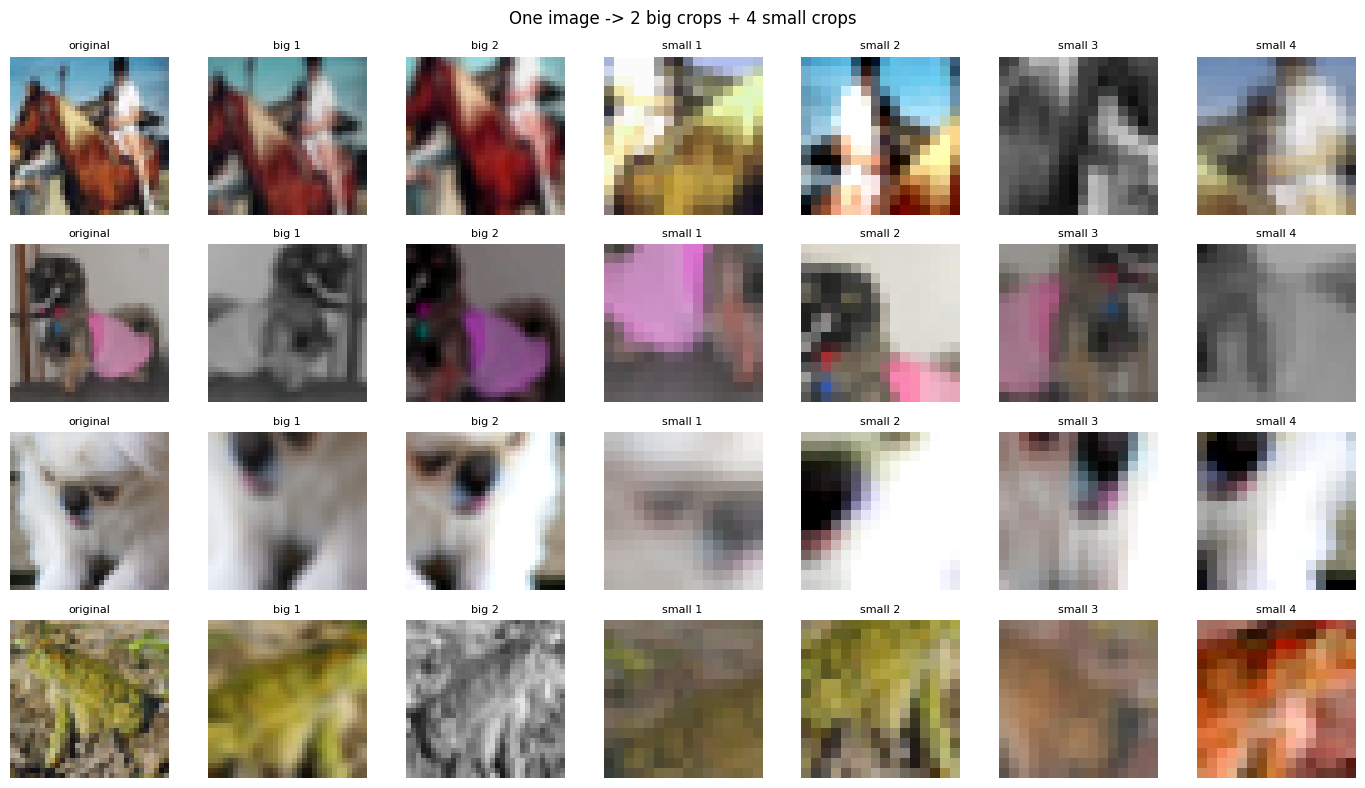

In [5]:
# show crops from 4 images
demo_aug = MultiCropAugmentation(N_LOCAL)
n_rows = 4
fig, axes = plt.subplots(n_rows, 2 + N_LOCAL + 1, figsize=(2 * (N_LOCAL + 3), 2 * n_rows))
for r in range(n_rows):
    image, _ = train_data[train_idx[r]]
    crops = demo_aug(image)
    axes[r, 0].imshow(image)
    axes[r, 0].set_title("original", fontsize=8)
    for c, crop in enumerate(crops):
        axes[r, c + 1].imshow(to_picture(crop))
        axes[r, c + 1].set_title("big %d" % (c + 1) if c < 2 else "small %d" % (c - 1), fontsize=8)
    for ax in axes[r]:
        ax.axis("off")
plt.suptitle("One image -> 2 big crops + %d small crops" % N_LOCAL)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "01_multicrop_examples.png"), dpi=150, bbox_inches="tight")
plt.show()

The big crops show most of the object, the small crops only a piece of it.

## Step 4: The student and teacher networks

Both are the same small vit.

In [6]:
class Attention(nn.Module):
    # self-attention
    def __init__(self, dim, heads):
        super().__init__()
        self.heads = heads
        self.scale = (dim // heads) ** -0.5
        self.to_qkv = nn.Linear(dim, dim * 3)
        self.out = nn.Linear(dim, dim)

    def forward(self, x):
        B, N, C = x.shape
        qkv = self.to_qkv(x).reshape(B, N, 3, self.heads, C // self.heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attention = (q @ k.transpose(-2, -1)) * self.scale
        attention = attention.softmax(dim=-1)          
        result = (attention @ v).transpose(1, 2).reshape(B, N, C)
        return self.out(result), attention


class TransformerBlock(nn.Module):
    # attention+MLP with skip connections
    def __init__(self, dim, heads):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attention = Attention(dim, heads)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = nn.Sequential(nn.Linear(dim, dim * 4), nn.GELU(), nn.Linear(dim * 4, dim))

    def forward(self, x, return_attention=False):
        attended, attention = self.attention(self.norm1(x))
        if return_attention:
            return attention
        x = x + attended
        x = x + self.mlp(self.norm2(x))
        return x


class TinyViT(nn.Module):
    def __init__(self):
        super().__init__()
        n_patches = (IMG_SIZE // PATCH_SIZE) ** 2
        self.patch_embed = nn.Conv2d(3, EMBED_DIM, kernel_size=PATCH_SIZE, stride=PATCH_SIZE)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, EMBED_DIM))
        self.pos_embed = nn.Parameter(torch.zeros(1, 1 + n_patches, EMBED_DIM))
        self.blocks = nn.ModuleList([TransformerBlock(EMBED_DIM, HEADS) for _ in range(DEPTH)])
        self.norm = nn.LayerNorm(EMBED_DIM, eps=1e-6)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.trunc_normal_(module.weight, std=0.02)
            nn.init.zeros_(module.bias)

    def interpolate_pos_encoding(self, n_patches_now):
        # resize position embeddings for smaller crops
        n_patches_saved = self.pos_embed.shape[1] - 1
        if n_patches_now == n_patches_saved:
            return self.pos_embed
        side_saved = int(math.sqrt(n_patches_saved))
        side_now = int(math.sqrt(n_patches_now))
        patch_pos = self.pos_embed[:, 1:].reshape(1, side_saved, side_saved, EMBED_DIM).permute(0, 3, 1, 2)
        patch_pos = F.interpolate(patch_pos, size=(side_now, side_now), mode="bicubic", align_corners=False)
        patch_pos = patch_pos.permute(0, 2, 3, 1).reshape(1, side_now * side_now, EMBED_DIM)
        return torch.cat([self.pos_embed[:, :1], patch_pos], dim=1)

    def make_tokens(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        cls = self.cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat([cls, x], dim=1)
        return x + self.interpolate_pos_encoding(x.shape[1] - 1)

    def forward(self, x):
        x = self.make_tokens(x)
        for block in self.blocks:
            x = block(x)
        x = self.norm(x)
        return x[:, 0]                                               

    @torch.no_grad()
    def last_layer_attention(self, x):
        # last block attention->used for attention maps
        x = self.make_tokens(x)
        for block in self.blocks[:-1]:
            x = block(x)
        return self.blocks[-1](x, return_attention=True)             

In [7]:
class DINOHead(nn.Module):
   
    def __init__(self, in_dim=EMBED_DIM, hidden=512, bottleneck=128, out_dim=OUT_DIM):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.GELU(),
            nn.Linear(hidden, hidden), nn.GELU(),
            nn.Linear(hidden, bottleneck))
        self.last_layer = nn.Parameter(torch.empty(out_dim, bottleneck))
        nn.init.trunc_normal_(self.last_layer, std=0.02)

    def forward(self, x):
        x = F.normalize(self.mlp(x), dim=-1)
        w = F.normalize(self.last_layer, dim=-1)
        return x @ w.T


class DINONet(nn.Module):

    def __init__(self):
        super().__init__()
        self.backbone = TinyViT()
        self.head = DINOHead()

    def forward(self, crops):
        
        groups = []
        for crop in crops:
            if groups and groups[-1][-1].shape[-1] == crop.shape[-1]:
                groups[-1].append(crop)
            else:
                groups.append([crop])
        embeddings = torch.cat([self.backbone(torch.cat(g)) for g in groups])
        return self.head(embeddings)


def build_student_and_teacher():
    student = DINONet()
    teacher = DINONet()
    teacher.load_state_dict(student.state_dict())     
    for p in teacher.parameters():
        p.requires_grad = False                      
    return student.to(device), teacher.to(device)

_tmp_student, _ = build_student_and_teacher()
print("Backbone parameters: %.2f million" % (sum(p.numel() for p in _tmp_student.backbone.parameters()) / 1e6))
print("Head parameters    : %.2f million" % (sum(p.numel() for p in _tmp_student.head.parameters()) / 1e6))
del _tmp_student

Backbone parameters: 2.69 million
Head parameters    : 0.69 million


## Step 5: The DINO loss and the EMA update


In [8]:
class DINOLoss(nn.Module):
    def __init__(self, n_crops, epochs):
        super().__init__()
        self.n_crops = n_crops
        # running center
        self.register_buffer("center", torch.zeros(1, OUT_DIM))
        # teacher temperature schedule
        warm = min(TEACHER_WARMUP_EPOCHS, epochs)
        self.temp_per_epoch = np.concatenate([
            np.linspace(TEACHER_TEMP_START, TEACHER_TEMP_END, warm),
            np.full(epochs - warm, TEACHER_TEMP_END)])
        self.stats = {}

    def forward(self, student_out, teacher_out, epoch):
        student_log_probs = F.log_softmax(student_out / STUDENT_TEMP, dim=-1).chunk(self.n_crops)

        teacher_temp = float(self.temp_per_epoch[epoch])
        teacher_probs = F.softmax((teacher_out - self.center) / teacher_temp, dim=-1).detach().chunk(2)

        total, n_pairs = 0.0, 0
        for t_idx, t_prob in enumerate(teacher_probs):
            for s_idx in range(self.n_crops):
                if s_idx == t_idx:
                    continue                                   
                cross_entropy = -(t_prob * student_log_probs[s_idx]).sum(dim=-1).mean()
                total = total + cross_entropy
                n_pairs += 1
        loss = total / n_pairs

       
        with torch.no_grad():
            entropy = float(np.mean([(-(p * torch.log(p + 1e-12)).sum(-1).mean()).item() for p in teacher_probs]))
            self.stats = {"teacher_entropy": entropy, "kl": loss.item() - entropy, "teacher_temp": teacher_temp}
          
            batch_center = teacher_out.mean(dim=0, keepdim=True)
            self.center = self.center * CENTER_MOMENTUM + batch_center * (1 - CENTER_MOMENTUM)
        return loss


@torch.no_grad()
def ema_update(student, teacher, m):
    # teacher=m*teacher+(1-m)*student
    for p_student, p_teacher in zip(student.parameters(), teacher.parameters()):
        p_teacher.data.mul_(m).add_(p_student.data, alpha=1 - m)

### k-NN accuracy
Since there are no labels in training, we measure quality with a k-NN test on the embeddings.

In [9]:
@torch.no_grad()
def get_embeddings(backbone, images, batch=500):
    backbone.eval()
    out = []
    for i in range(0, len(images), batch):
        out.append(backbone(images[i:i + batch].to(device)).cpu())
    return torch.cat(out)


@torch.no_grad()
def knn_accuracy(backbone, k=20, temperature=0.07):
    train_emb = F.normalize(get_embeddings(backbone, PLAIN_TRAIN_X), dim=1).to(device)
    test_emb = F.normalize(get_embeddings(backbone, PLAIN_TEST_X), dim=1).to(device)
    train_y = torch.from_numpy(train_labels).long().to(device)
    test_y = torch.from_numpy(test_labels).long().to(device)

    similarity = test_emb @ train_emb.T
    top_sim, top_idx = similarity.topk(k, dim=1)
    neighbour_classes = train_y[top_idx]
    weights = (top_sim / temperature).exp()

    votes = torch.zeros(len(test_emb), 10, device=device)
    votes.scatter_add_(1, neighbour_classes, weights)
    predictions = votes.argmax(dim=1)
    return (predictions == test_y).float().mean().item()

## Step 6: Sanity checks before training

Check 1: output shapes, student == teacher at the start, gradients reach only the student.

Check 2: the EMA update matches the formula, including m = 1 and m = 0.

In [10]:
set_seed(SEED)
N_CROPS = 2 + N_LOCAL

check_loader = DataLoader(UnlabeledCropDataset(train_data, train_idx, MultiCropAugmentation(N_LOCAL)),
                          batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=0)
crops = [c.to(device) for c in next(iter(check_loader))]
print("Crop shapes:", [tuple(c.shape) for c in crops])

student, teacher = build_student_and_teacher()
loss_fn = DINOLoss(N_CROPS, EPOCHS).to(device)

student_out = student(crops)                  # student sees all crops
with torch.no_grad():
    teacher_out = teacher(crops[:2])          # teacher sees only the 2 big crops

print("Student output shape:", tuple(student_out.shape), "(expected %d x %d)" % (BATCH_SIZE * N_CROPS, OUT_DIM))
print("Teacher output shape:", tuple(teacher_out.shape), "(expected %d x %d)" % (BATCH_SIZE * 2, OUT_DIM))
assert student_out.shape == (BATCH_SIZE * N_CROPS, OUT_DIM)
assert teacher_out.shape == (BATCH_SIZE * 2, OUT_DIM)

#student==teacher at start
with torch.no_grad():
    student_on_big = student(crops[:2])
difference = (student_on_big - teacher_out).abs().max().item()
print("Biggest difference student vs teacher on big crops at start: %.8f" % difference)
assert difference < 1e-4

loss = loss_fn(student_out, teacher_out, epoch=0)
print("Loss at the start: %.3f  (a completely 'clueless' answer would be about ln(K) = %.3f)" % (loss.item(), math.log(OUT_DIM)))
print("Teacher entropy at the start: %.3f  (the maximum possible is ln(K) = %.3f)" % (loss_fn.stats["teacher_entropy"], math.log(OUT_DIM)))

#gradients only reach the student
loss.backward()
assert all(p.grad is None for p in teacher.parameters())
assert all(p.grad is not None for p in student.parameters())
print("Check 1 passed: gradients flow into the student only.")

Crop shapes: [(64, 3, 32, 32), (64, 3, 32, 32), (64, 3, 16, 16), (64, 3, 16, 16), (64, 3, 16, 16), (64, 3, 16, 16)]
Student output shape: (384, 2048) (expected 384 x 2048)
Teacher output shape: (128, 2048) (expected 128 x 2048)
Biggest difference student vs teacher on big crops at start: 0.00000000
Loss at the start: 6.754  (a completely 'clueless' answer would be about ln(K) = 7.625)
Teacher entropy at the start: 5.316  (the maximum possible is ln(K) = 7.625)
Check 1 passed: gradients flow into the student only.


In [11]:
# Check 2: the EMA update
optimizer_check = torch.optim.AdamW(student.parameters(), lr=1e-3)
optimizer_check.step()

teacher_before = [p.detach().clone() for p in teacher.parameters()]
student_now = [p.detach().clone() for p in student.parameters()]

m = 0.9
ema_update(student, teacher, m)
worst_error = max(
    (p_t.detach() - (m * old + (1 - m) * new)).abs().max().item()
    for p_t, old, new in zip(teacher.parameters(), teacher_before, student_now))
print("m = 0.9 -> largest error vs the formula: %.2e" % worst_error)
assert worst_error < 1e-6

snapshot = [p.detach().clone() for p in teacher.parameters()]
ema_update(student, teacher, 1.0)             #m=1:teacher unchanged
assert all(torch.equal(a, b.detach()) for a, b in zip(snapshot, teacher.parameters()))
print("m = 1.0 -> teacher unchanged (OK)")

ema_update(student, teacher, 0.0)             #m=0:teacher = student
assert all(torch.allclose(a.detach(), b.detach()) for a, b in zip(student.parameters(), teacher.parameters()))
print("m = 0.0 -> teacher became a copy of the student (OK)")
print("Check 2 passed: the EMA update works as expected.")

del student, teacher, loss_fn, optimizer_check, check_loader

m = 0.9 -> largest error vs the formula: 1.49e-08
m = 1.0 -> teacher unchanged (OK)
m = 0.0 -> teacher became a copy of the student (OK)
Check 2 passed: the EMA update works as expected.


## Step 7: Training

Each step: make the crops, run the teacher (global crops) and student (all crops), compute the DINO loss, update the student with AdamW, then update the teacher with EMA.

`train_dino` takes `use_ema` and `n_local` for the ablations.

In [12]:
def train_dino(name, use_ema=True, n_local=N_LOCAL, epochs=EPOCHS):
    set_seed(SEED)
    n_crops = 2 + n_local

    loader = DataLoader(
        UnlabeledCropDataset(train_data, train_idx, MultiCropAugmentation(n_local)),
        batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
        num_workers=2, pin_memory=(device.type == "cuda"))
    steps_per_epoch = len(loader)

    student, teacher = build_student_and_teacher()
    loss_fn = DINOLoss(n_crops, epochs).to(device)
    optimizer = torch.optim.AdamW(student.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

    log = {"name": name, "step_loss": [], "epoch_loss": [], "teacher_entropy": [], "kl": [],
           "weight_distance": [], "knn_epochs": [], "knn_teacher": [], "knn_student": []}

    # k-NN before training
    log["knn_epochs"].append(0)
    log["knn_teacher"].append(knn_accuracy(teacher.backbone))
    log["knn_student"].append(knn_accuracy(student.backbone))
    print("[%s] epoch 0 (untrained): kNN accuracy = %.1f%%" % (name, 100 * log["knn_teacher"][0]))

    start_time = time.time()
    for epoch in range(epochs):
        student.train()

        # lr:warm-up,then cosine decay
        if epoch < WARMUP_EPOCHS:
            lr = LEARNING_RATE * (epoch + 1) / WARMUP_EPOCHS
        else:
            progress = (epoch - WARMUP_EPOCHS) / max(1, epochs - WARMUP_EPOCHS)
            lr = 1e-6 + 0.5 * (LEARNING_RATE - 1e-6) * (1 + math.cos(math.pi * progress))
        for group in optimizer.param_groups:
            group["lr"] = lr

        # teacher momentum m
        if use_ema:
            m = 1 - (1 - EMA_START) * (math.cos(math.pi * epoch / epochs) + 1) / 2
        else:
            m = 0.0                               

        losses, entropies, kls = [], [], []
        for step, crops in enumerate(loader):
            crops = [c.to(device, non_blocking=True) for c in crops]

            with torch.no_grad():
                teacher_out = teacher(crops[:2])     
            student_out = student(crops)             

            loss = loss_fn(student_out, teacher_out, epoch)
            if not math.isfinite(loss.item()):
                raise RuntimeError("The loss became NaN/inf. Try lowering LEARNING_RATE and run again.")

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(student.parameters(), 3.0)   # gradient clipping
            optimizer.step()

            ema_update(student, teacher, m)          # EMA update

            losses.append(loss.item())
            entropies.append(loss_fn.stats["teacher_entropy"])
            kls.append(loss_fn.stats["kl"])
            log["step_loss"].append(loss.item())

            if epoch == 0 and step == 0:
                print("[%s] first batch: student output %s, teacher output %s, loss %.3f" %
                      (name, tuple(student_out.shape), tuple(teacher_out.shape), loss.item()))

        # student-teacher weight distance
        with torch.no_grad():
            distance = math.sqrt(sum(((a - b) ** 2).sum().item()
                                     for a, b in zip(student.backbone.parameters(), teacher.backbone.parameters())))
        log["epoch_loss"].append(float(np.mean(losses)))
        log["teacher_entropy"].append(float(np.mean(entropies)))
        log["kl"].append(float(np.mean(kls)))
        log["weight_distance"].append(distance)

        message = "[%s] epoch %2d/%d | loss %.3f | T-entropy %.2f/%.2f | KL %.3f | dist %.2f | m %.4f" % (
            name, epoch + 1, epochs, log["epoch_loss"][-1], log["teacher_entropy"][-1],
            math.log(OUT_DIM), log["kl"][-1], distance, m)
        if (epoch + 1) % EVAL_EVERY == 0 or epoch + 1 == epochs:
            log["knn_epochs"].append(epoch + 1)
            log["knn_teacher"].append(knn_accuracy(teacher.backbone))
            log["knn_student"].append(knn_accuracy(student.backbone))
            message += " | kNN teacher %.1f%% student %.1f%%" % (100 * log["knn_teacher"][-1], 100 * log["knn_student"][-1])
        print(message + " | %.0fs" % (time.time() - start_time))

    return {"log": log, "student": student, "teacher": teacher, "epochs": epochs}

In [13]:
# Train the main model
main_run = train_dino("EMA teacher")
torch.save(main_run["teacher"].state_dict(), os.path.join(BASE_DIR, "mini_dino_teacher.pt"))

[EMA teacher] epoch 0 (untrained): kNN accuracy = 25.7%
[EMA teacher] first batch: student output (384, 2048), teacher output (128, 2048), loss 6.732
[EMA teacher] epoch  1/20 | loss 7.014 | T-entropy 6.32/7.62 | KL 0.697 | dist 0.75 | m 0.9900 | 22s
[EMA teacher] epoch  2/20 | loss 7.158 | T-entropy 6.70/7.62 | KL 0.456 | dist 1.13 | m 0.9901 | kNN teacher 24.4% student 24.4% | 46s
[EMA teacher] epoch  3/20 | loss 7.287 | T-entropy 6.88/7.62 | KL 0.404 | dist 1.18 | m 0.9902 | 67s
[EMA teacher] epoch  4/20 | loss 7.259 | T-entropy 6.85/7.62 | KL 0.409 | dist 1.21 | m 0.9905 | kNN teacher 25.3% student 27.7% | 92s
[EMA teacher] epoch  5/20 | loss 7.195 | T-entropy 6.75/7.62 | KL 0.449 | dist 1.30 | m 0.9910 | 115s
[EMA teacher] epoch  6/20 | loss 7.127 | T-entropy 6.63/7.62 | KL 0.498 | dist 1.35 | m 0.9915 | kNN teacher 27.4% student 27.5% | 139s
[EMA teacher] epoch  7/20 | loss 7.071 | T-entropy 6.53/7.62 | KL 0.541 | dist 1.32 | m 0.9921 | 161s
[EMA teacher] epoch  8/20 | loss 6.997

## Step 8: Training curves

Loss, collapse check (teacher entropy and KL) and k-NN accuracy.

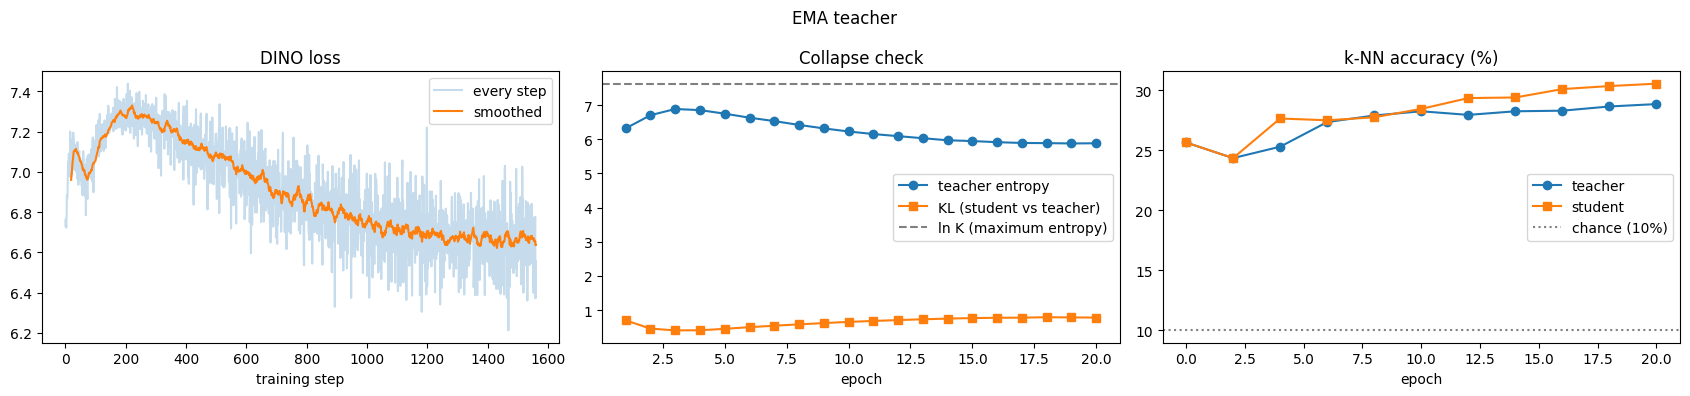

k-NN accuracy before training: 25.7%
k-NN accuracy after training (teacher): 28.9%, (student): 30.6%


In [14]:
def smooth(values, window=20):
    values = np.asarray(values)
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

def plot_run(run, filename):
    log = run["log"]
    epochs = run["epochs"]
    steps_per_epoch = len(log["step_loss"]) // epochs
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))

    # 1) loss
    axes[0].plot(log["step_loss"], alpha=0.25, label="every step")
    axes[0].plot(np.arange(len(smooth(log["step_loss"]))) + 19, smooth(log["step_loss"]), label="smoothed")
    axes[0].set_title("DINO loss"); axes[0].set_xlabel("training step"); axes[0].legend()

    # 2) collapse diagnostics
    x = np.arange(1, epochs + 1)
    axes[1].plot(x, log["teacher_entropy"], "o-", label="teacher entropy")
    axes[1].plot(x, log["kl"], "s-", label="KL (student vs teacher)")
    axes[1].axhline(math.log(OUT_DIM), color="gray", linestyle="--", label="ln K (maximum entropy)")
    axes[1].set_title("Collapse check"); axes[1].set_xlabel("epoch"); axes[1].legend()

    # 3) k-NN accuracy
    axes[2].plot(log["knn_epochs"], [100 * a for a in log["knn_teacher"]], "o-", label="teacher")
    axes[2].plot(log["knn_epochs"], [100 * a for a in log["knn_student"]], "s-", label="student")
    axes[2].axhline(10, color="gray", linestyle=":", label="chance (10%)")
    axes[2].set_title("k-NN accuracy (%)"); axes[2].set_xlabel("epoch"); axes[2].legend()

    plt.suptitle(log["name"])
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename), dpi=150, bbox_inches="tight")
    plt.show()

plot_run(main_run, "02_training_curves.png")

main_log = main_run["log"]
print("k-NN accuracy before training: %.1f%%" % (100 * main_log["knn_teacher"][0]))
print("k-NN accuracy after training (teacher): %.1f%%, (student): %.1f%%" %
      (100 * main_log["knn_teacher"][-1], 100 * main_log["knn_student"][-1]))

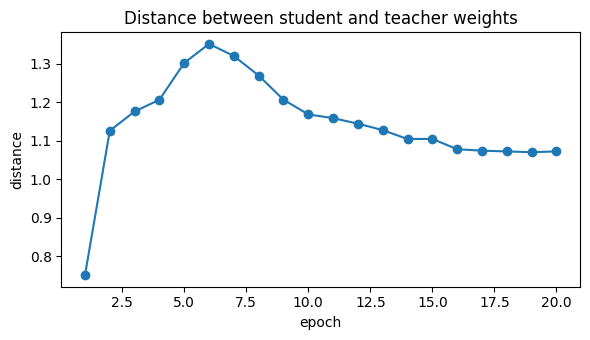

In [15]:
# student-teacher weight distance
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, EPOCHS + 1), main_log["weight_distance"], "o-")
plt.title("Distance between student and teacher weights")
plt.xlabel("epoch"); plt.ylabel("distance")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "03_student_teacher_distance.png"), dpi=150, bbox_inches="tight")
plt.show()

## Step 9: Embeddings (PCA and t-SNE)

2D plots of the embeddings, coloured by true class, compared with an untrained ViT.

k-NN accuracy: untrained 25.7%  vs  Mini-DINO teacher 28.9%


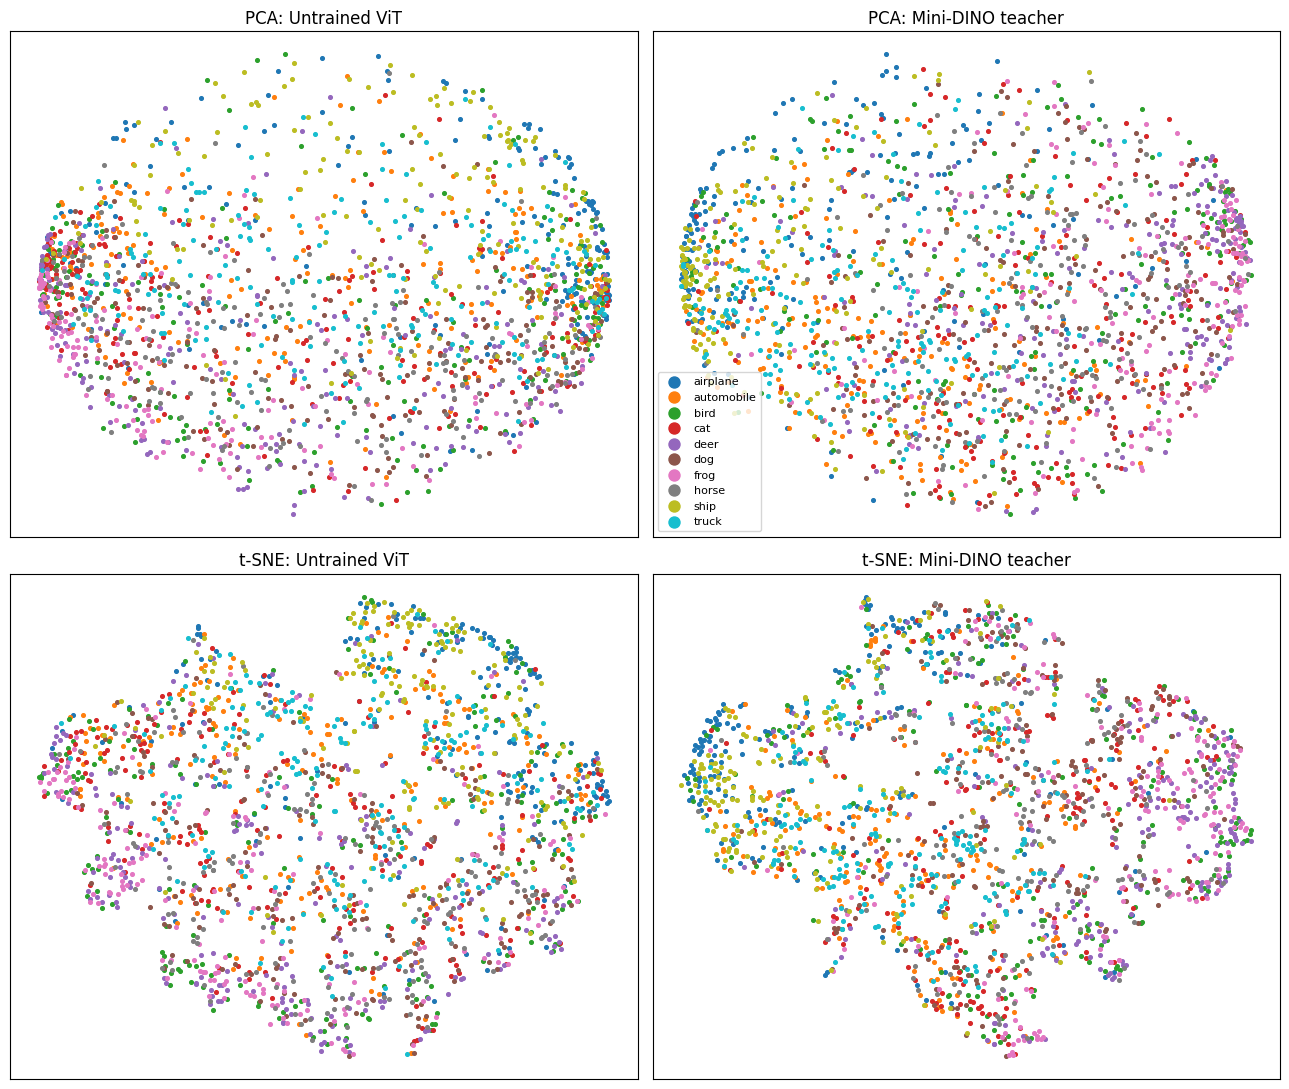

In [16]:
set_seed(SEED)
untrained_backbone = TinyViT().to(device)                    # untrained baseline

embeddings = {
    "Untrained ViT": get_embeddings(untrained_backbone, PLAIN_TEST_X).numpy(),
    "Mini-DINO teacher": get_embeddings(main_run["teacher"].backbone, PLAIN_TEST_X).numpy(),
}
knn_untrained = knn_accuracy(untrained_backbone)
knn_trained = knn_accuracy(main_run["teacher"].backbone)
print("k-NN accuracy: untrained %.1f%%  vs  Mini-DINO teacher %.1f%%" % (100 * knn_untrained, 100 * knn_trained))

colors = plt.get_cmap("tab10")
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for col, (title, emb) in enumerate(embeddings.items()):
    pca_2d = PCA(n_components=2, random_state=0).fit_transform(emb)
    # PCA to 50 dims before t-SNE
    pca_50 = PCA(n_components=50, random_state=0).fit_transform(emb)
    tsne_2d = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=0).fit_transform(pca_50)

    for row, (points, method) in enumerate([(pca_2d, "PCA"), (tsne_2d, "t-SNE")]):
        ax = axes[row, col]
        for c in range(10):
            mask = test_labels == c
            ax.scatter(points[mask, 0], points[mask, 1], s=7, color=colors(c), label=CLASS_NAMES[c])
        ax.set_title("%s: %s" % (method, title))
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 1].legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "04_embeddings_pca_tsne.png"), dpi=150, bbox_inches="tight")
plt.show()

Compare the untrained (left) and DINO (right) columns for more same-coloured groups.

## Step 10: Attention maps

[CLS] attention from the last block, shown per head and averaged, compared with the untrained model.

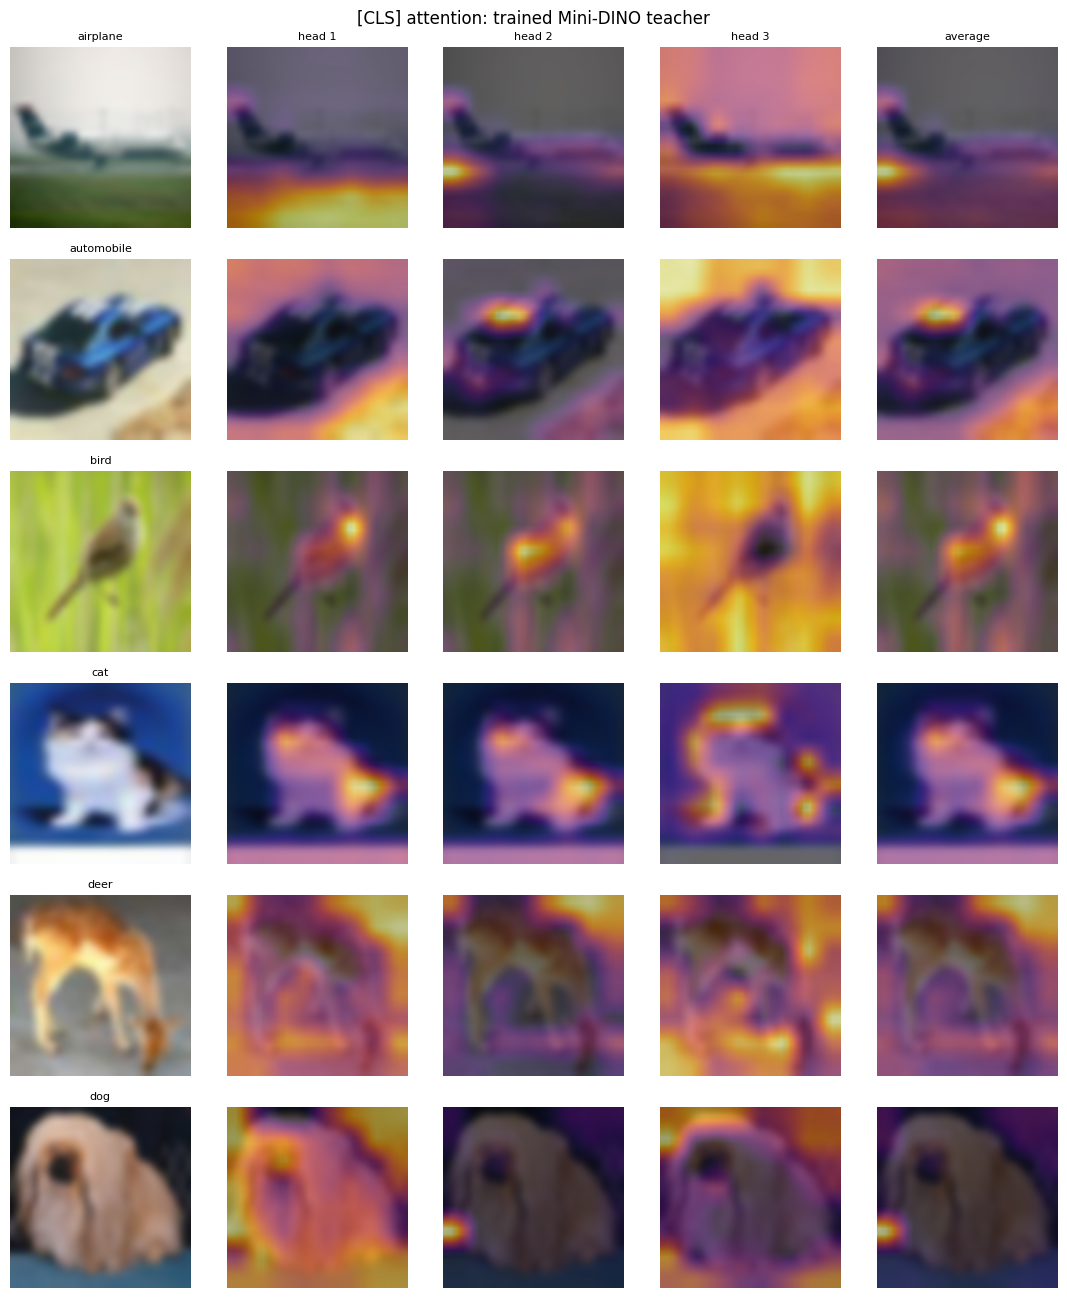

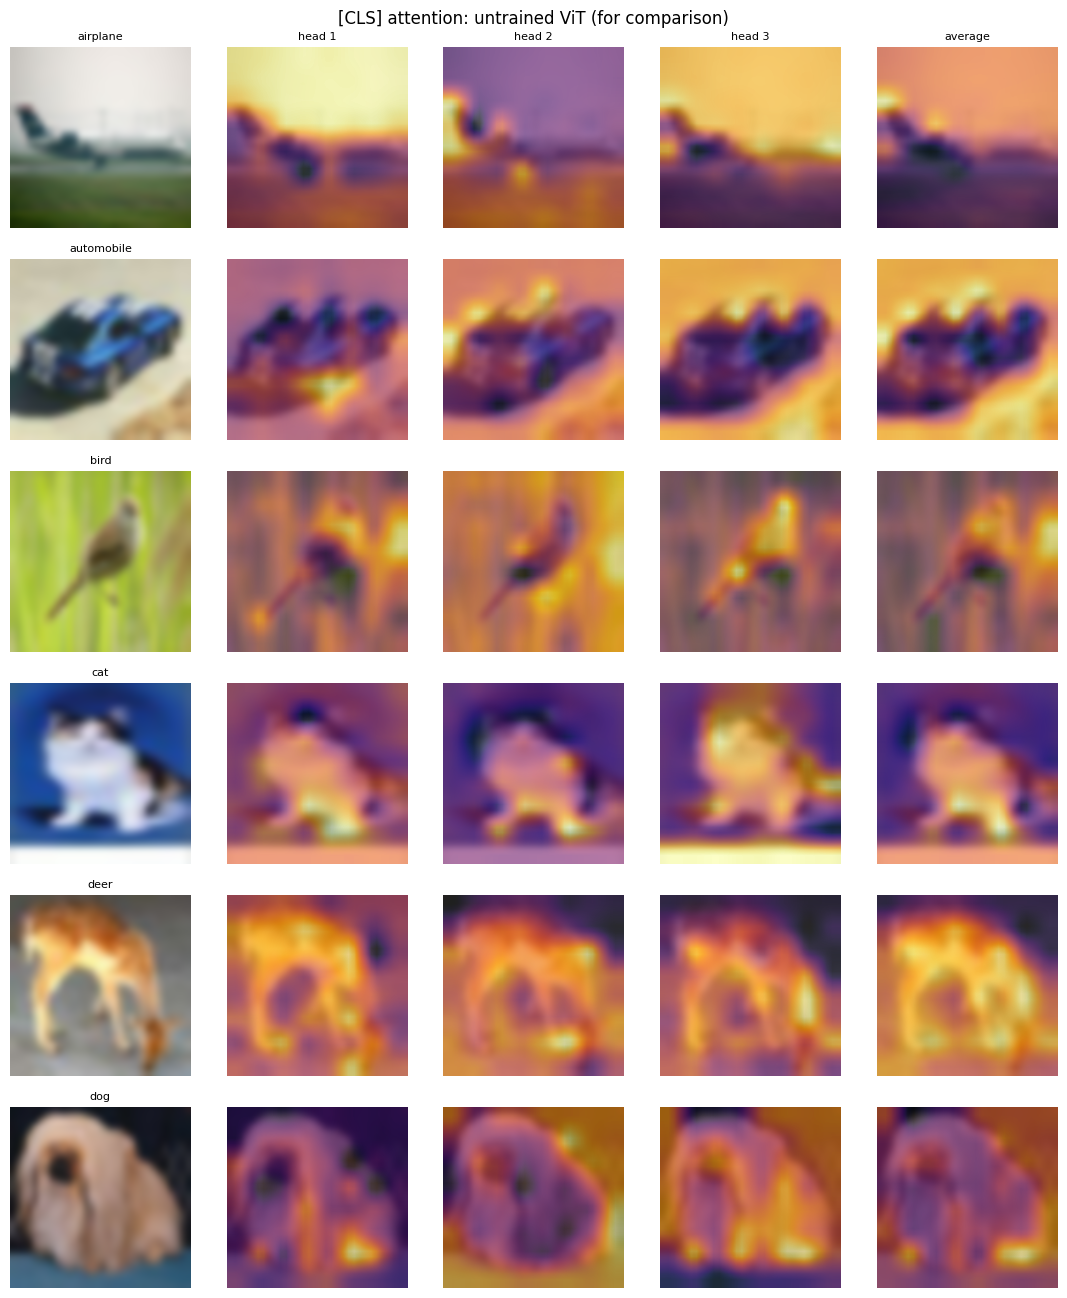

In [17]:
def show_attention(backbone, title, filename):
    # one image from each of the first 6 classes
    chosen = [int(np.where(test_labels == c)[0][0]) for c in range(6)]
    images = PLAIN_TEST_X[chosen].to(device)

    backbone.eval()
    attention = backbone.last_layer_attention(images)
    attention = attention[:, :, 0, 1:]                         # [CLS] row, skip itself
    n_images, n_heads, n_patches = attention.shape
    side = int(math.sqrt(n_patches))
    attention = attention.reshape(n_images, n_heads, side, side)
    attention = F.interpolate(attention, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False).cpu()
    average = attention.mean(dim=1, keepdim=True)              # average over heads
    all_maps = torch.cat([attention, average], dim=1)

    fig, axes = plt.subplots(n_images, n_heads + 2, figsize=(2.2 * (n_heads + 2), 2.2 * n_images))
    for r in range(n_images):
        picture = to_picture(images[r])
        axes[r, 0].imshow(picture, interpolation="bicubic")
        axes[r, 0].set_title(CLASS_NAMES[test_labels[chosen[r]]], fontsize=8)
        for h in range(n_heads + 1):
            heat = all_maps[r, h].numpy()
            heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)   # rescale to 0..1
            axes[r, h + 1].imshow(picture, interpolation="bicubic")
            axes[r, h + 1].imshow(heat, cmap="inferno", alpha=0.6, interpolation="bilinear")
            if r == 0:
                axes[r, h + 1].set_title("head %d" % (h + 1) if h < n_heads else "average", fontsize=8)
        for ax in axes[r]:
            ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename), dpi=150, bbox_inches="tight")
    plt.show()

show_attention(main_run["teacher"].backbone, "[CLS] attention: trained Mini-DINO teacher", "05_attention_dino_teacher.png")
show_attention(untrained_backbone, "[CLS] attention: untrained ViT (for comparison)", "06_attention_untrained.png")

Check whether the trained model's attention is more focused on the object than the untrained one.

## Step 11: Ablation: without the EMA teacher

Same training, same seed, one change: the teacher is a plain copy of the student (m = 0) instead of an EMA.

[No EMA (teacher = student copy)] epoch 0 (untrained): kNN accuracy = 25.7%
[No EMA (teacher = student copy)] first batch: student output (384, 2048), teacher output (128, 2048), loss 6.732
[No EMA (teacher = student copy)] epoch  1/20 | loss 3.928 | T-entropy 2.86/7.62 | KL 1.068 | dist 0.00 | m 0.0000 | 21s
[No EMA (teacher = student copy)] epoch  2/20 | loss 3.928 | T-entropy 3.04/7.62 | KL 0.887 | dist 0.00 | m 0.0000 | kNN teacher 26.5% student 26.5% | 46s
[No EMA (teacher = student copy)] epoch  3/20 | loss 3.214 | T-entropy 1.52/7.62 | KL 1.693 | dist 0.00 | m 0.0000 | 68s
[No EMA (teacher = student copy)] epoch  4/20 | loss 4.019 | T-entropy 2.74/7.62 | KL 1.274 | dist 0.00 | m 0.0000 | kNN teacher 28.4% student 28.4% | 93s
[No EMA (teacher = student copy)] epoch  5/20 | loss 3.943 | T-entropy 2.91/7.62 | KL 1.037 | dist 0.00 | m 0.0000 | 114s
[No EMA (teacher = student copy)] epoch  6/20 | loss 4.717 | T-entropy 3.38/7.62 | KL 1.333 | dist 0.00 | m 0.0000 | kNN teacher 24.8% s

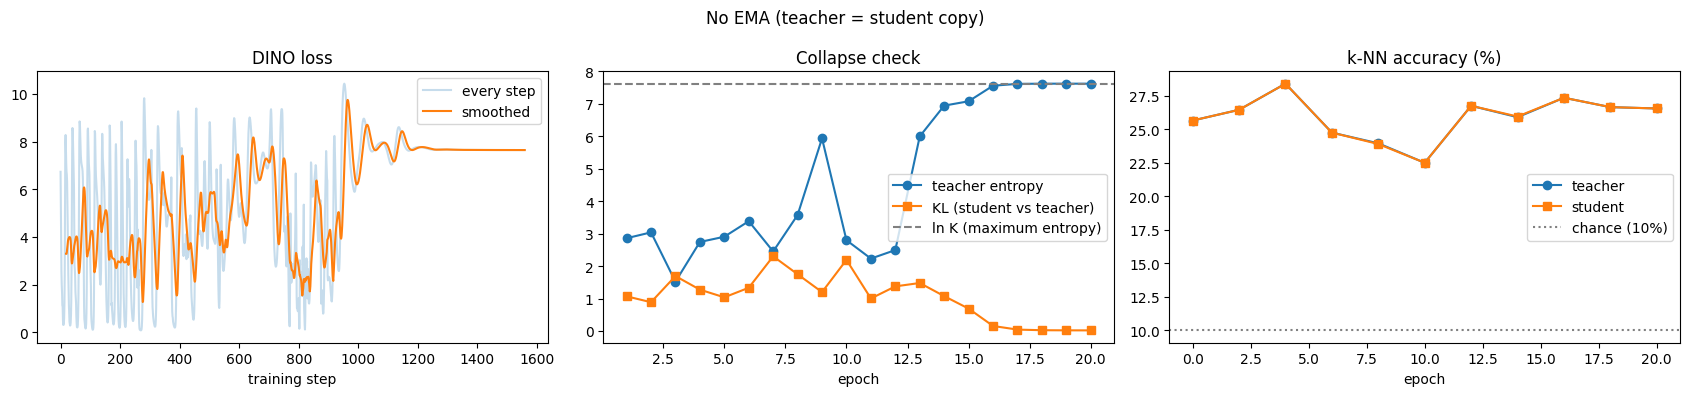

In [18]:
no_ema_run = train_dino("No EMA (teacher = student copy)", use_ema=False)
plot_run(no_ema_run, "07_training_curves_no_ema.png")

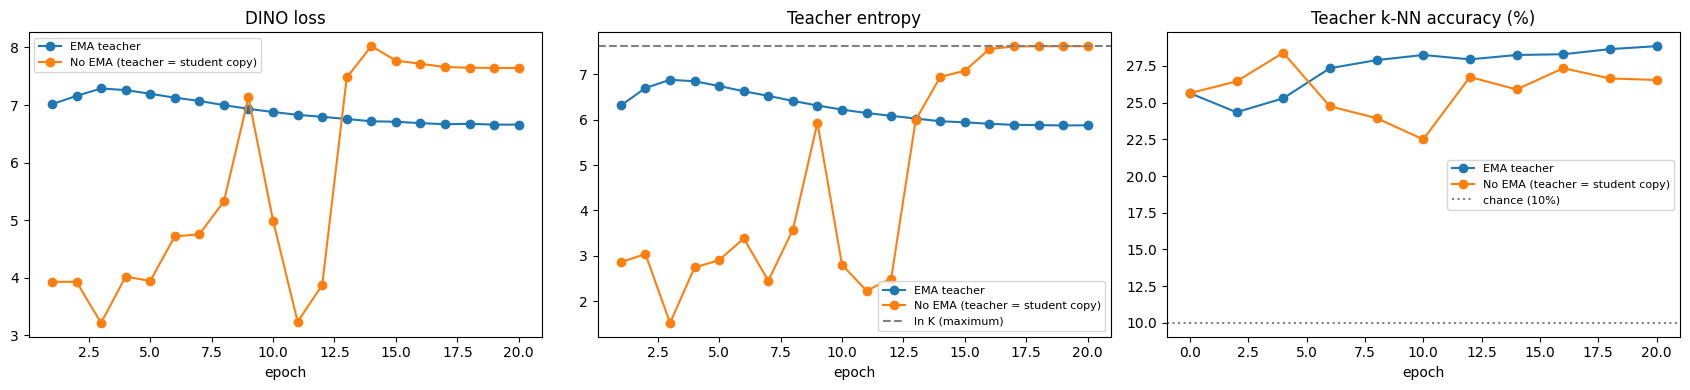

Run                                  Final loss   kNN teacher    kNN student   
EMA teacher                          6.659        28.9%          30.6%         
No EMA (teacher = student copy)      7.643        26.6%          26.6%         


In [19]:
def plot_comparison(runs, filename):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for run in runs:
        log = run["log"]
        x = np.arange(1, len(log["epoch_loss"]) + 1)
        axes[0].plot(x, log["epoch_loss"], "o-", label=log["name"])
        axes[1].plot(x, log["teacher_entropy"], "o-", label=log["name"])
        axes[2].plot(log["knn_epochs"], [100 * a for a in log["knn_teacher"]], "o-", label=log["name"])
    axes[0].set_title("DINO loss"); axes[0].set_xlabel("epoch")
    axes[1].axhline(math.log(OUT_DIM), color="gray", linestyle="--", label="ln K (maximum)")
    axes[1].set_title("Teacher entropy"); axes[1].set_xlabel("epoch")
    axes[2].axhline(10, color="gray", linestyle=":", label="chance (10%)")
    axes[2].set_title("Teacher k-NN accuracy (%)"); axes[2].set_xlabel("epoch")
    for ax in axes:
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename), dpi=150, bbox_inches="tight")
    plt.show()

plot_comparison([main_run, no_ema_run], "08_ablation_ema_vs_no_ema.png")

print("%-36s %-12s %-14s %-14s" % ("Run", "Final loss", "kNN teacher", "kNN student"))
for run in (main_run, no_ema_run):
    log = run["log"]
    print("%-36s %-12.3f %-14s %-14s" % (log["name"], log["epoch_loss"][-1],
                                          "%.1f%%" % (100 * log["knn_teacher"][-1]),
                                          "%.1f%%" % (100 * log["knn_student"][-1])))

**How to read it:** a collapse shows as teacher entropy or KL going to ~0, and the EMA helps if its k-NN accuracy is higher. Similar results are also a valid finding.

Optionally, set the switch below to `True` to run a second ablation without the small crops.

In [20]:
# Optional ablation: no small crops
RUN_CROP_ABLATION = False

crops_run = None
if RUN_CROP_ABLATION:
    crops_run = train_dino("Only 2 big crops (no small crops)", n_local=0)
    plot_comparison([main_run, crops_run], "09_ablation_multicrop.png")

## Step 12: Save everything

Saves the summary table and metrics into `results/` and zips the folder for download.

In [21]:
all_runs = [main_run, no_ema_run] + ([crops_run] if crops_run is not None else [])

# summary table
rows = ["| Run | Final loss | Teacher entropy (max %.2f) | kNN teacher | kNN student |" % math.log(OUT_DIM),
        "|---|---|---|---|---|"]
for run in all_runs:
    log = run["log"]
    rows.append("| %s | %.3f | %.2f | %.1f%% | %.1f%% |" % (
        log["name"], log["epoch_loss"][-1], log["teacher_entropy"][-1],
        100 * log["knn_teacher"][-1], 100 * log["knn_student"][-1]))
rows.append("")
rows.append("Untrained ViT kNN accuracy: %.1f%%" % (100 * knn_untrained))
summary_text = "\n".join(rows)
print(summary_text)

with open(os.path.join(RESULTS_DIR, "summary.md"), "w") as f:
    f.write(summary_text)

# metrics
settings = {"N_TRAIN": N_TRAIN, "EPOCHS": EPOCHS, "BATCH_SIZE": BATCH_SIZE, "LEARNING_RATE": LEARNING_RATE,
            "N_LOCAL": N_LOCAL, "OUT_DIM": OUT_DIM, "EMA_START": EMA_START, "EMBED_DIM": EMBED_DIM,
            "DEPTH": DEPTH, "HEADS": HEADS, "PATCH_SIZE": PATCH_SIZE, "SEED": SEED}
with open(os.path.join(RESULTS_DIR, "metrics.json"), "w") as f:
    json.dump({"settings": settings, "runs": [r["log"] for r in all_runs],
               "knn_untrained": knn_untrained}, f, indent=2)

zip_path = shutil.make_archive(os.path.join(BASE_DIR, "week2_results"), "zip", RESULTS_DIR)
print("\nFiles saved in results/:", sorted(os.listdir(RESULTS_DIR)))
print("Zip file for download:", zip_path)

| Run | Final loss | Teacher entropy (max 7.62) | kNN teacher | kNN student |
|---|---|---|---|---|
| EMA teacher | 6.659 | 5.88 | 28.9% | 30.6% |
| No EMA (teacher = student copy) | 7.643 | 7.62 | 26.6% | 26.6% |

Untrained ViT kNN accuracy: 25.7%

Files saved in results/: ['00_dataset_samples.png', '01_multicrop_examples.png', '02_training_curves.png', '03_student_teacher_distance.png', '04_embeddings_pca_tsne.png', '05_attention_dino_teacher.png', '06_attention_untrained.png', '07_training_curves_no_ema.png', '08_ablation_ema_vs_no_ema.png', 'metrics.json', 'summary.md']
Zip file for download: /kaggle/working/week2_results.zip


## Notes for the report

1. **Training:** loss and teacher entropy, any sign of collapse?
2. **Student vs teacher:** k-NN accuracy and weight distance.
3. **Embeddings:** class structure in PCA / t-SNE vs untrained.
4. **Attention maps:** do the heads focus on objects?
5. **Ablation:** what changed without EMA?
6. **Limitations:** 5,000 images, tiny model, 20 epochs, K = 2048, one seed.

### Common problems
* **No GPU found:** turn on the GPU in Session options and re-run.
* **CIFAR-10 download fails:** turn Internet On.
* **Loss becomes NaN:** lower `LEARNING_RATE` (e.g. `2e-4`).
* **Out of memory:** lower `BATCH_SIZE` (e.g. `32`).